# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Akbar Fadil
- NIM   : 241011400573
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 73    # 2 digit terakhir NIM 241011400573 -> 73

In [2]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 data pertama:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data : 40
Shape X : (40, 1)
Shape y : (40,)


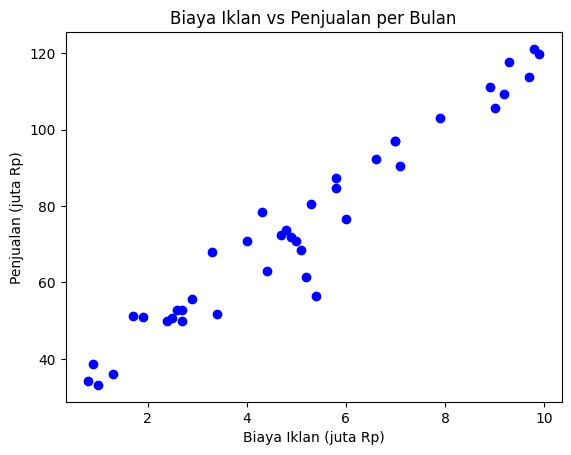

In [3]:
# Jawaban A1
ads_data = pd.read_csv('Ads_Data.csv')
print('5 data pertama:')
display(ads_data.head())
print('Jumlah baris data :', len(ads_data))

# X harus 2 dimensi (n, 1) -> pakai [['BiayaIklan']] agar tetap DataFrame, lalu .values
X = ads_data[['BiayaIklan']].values
y = ads_data['Penjualan'].values
print('Shape X :', X.shape)
print('Shape y :', y.shape)
assert X.ndim == 2 and X.shape[1] == 1

plt.scatter(X, y, c='blue')
plt.title('Biaya Iklan vs Penjualan per Bulan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
# Implementasi Linear Regression (normal equation) disalin dari materi
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_


regressor = LinearRegression()
regressor.fit(X_train, y_train)

b_ne = regressor.intercept_
m_ne = regressor.coefficients_[0]
print(f'Intercept (b)  : {b_ne:.4f}')
print(f'Koefisien (m)  : {m_ne:.4f}')
print(f'Persamaan      : y_hat = {b_ne:.4f} + {m_ne:.4f} * X')

Intercept (b)  : 29.0444
Koefisien (m)  : 8.9912
Persamaan      : y_hat = 29.0444 + 8.9912 * X


**Jawaban A3 (interpretasi):**

Dari data training (32 data) diperoleh intercept b = 29,0444 dan koefisien m = 8,9912, sehingga persamaan garisnya ŷ = 29,0444 + 8,9912·X. Nilai m = 8,99 berarti setiap kenaikan biaya iklan 1 juta Rp diikuti kenaikan penjualan sekitar 8,99 juta Rp per bulan (dengan asumsi hubungan linear). Nilai b = 29,04 adalah perkiraan penjualan ketika biaya iklan 0, tetapi data kita baru dimulai dari biaya iklan 0,8 juta sehingga angka ini lebih tepat dibaca sebagai titik potong garis, bukan penjualan nyata tanpa iklan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
# Metrik evaluasi regresi (implementasi sendiri dengan NumPy)
def mae(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    if ss_tot == 0:          # semua y sama -> R^2 tidak terdefinisi
        return np.nan
    return 1 - ss_res / ss_tot

y_pred_train = regressor.predict(X_train)
y_pred_test = regressor.predict(X_test)

hasil_eval = pd.DataFrame({
    'Training': [mae(y_train, y_pred_train), mse(y_train, y_pred_train),
                 rmse(y_train, y_pred_train), r2_score(y_train, y_pred_train)],
    'Testing':  [mae(y_test, y_pred_test), mse(y_test, y_pred_test),
                 rmse(y_test, y_pred_test), r2_score(y_test, y_pred_test)],
}, index=['MAE', 'MSE', 'RMSE', 'R2'])
display(hasil_eval.round(4))
print('Rata-rata Penjualan (y) data testing :', round(y_test.mean(), 4))
print('Rentang Penjualan seluruh data       :', y.min(), '-', y.max())

,Training,Testing
MAE,4.9225,2.9905
MSE,41.5429,14.7567
RMSE,6.4454,3.8414
R2,0.9261,0.9785


Rata-rata Penjualan (y) data testing : 60.525
Rentang Penjualan seluruh data       : 33.2 - 121.1


**Jawaban A4 (analisis):**

RMSE adalah rata-rata kesalahan prediksi dalam satuan asli (juta Rp). Pada data testing RMSE = 3,84, artinya prediksi meleset sekitar 3,84 juta Rp dari penjualan sebenarnya, atau sekitar 6% dari rata-rata penjualan testing (60,5 juta). Pada data training RMSE = 6,45. R² testing = 0,9785 dan R² training = 0,9261, jadi sekitar 93%–98% variasi penjualan dapat dijelaskan oleh biaya iklan.

Menurut saya model ini sudah baik untuk data ini karena pola datanya memang mendekati garis lurus, dan tidak terlihat tanda overfitting (error testing tidak lebih buruk dari training). Namun error testing yang lebih kecil dari training bukan berarti model lebih bagus di data baru, melainkan karena data testing hanya 8 titik sehingga kebetulan lebih mudah diprediksi. Model juga hanya memakai satu fitur (biaya iklan), jadi faktor lain seperti musim atau harga belum tertangkap.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

--- learning_rate = 0.001 ---
--- learning_rate = 0.02 ---
--- learning_rate = 0.1 ---


c:\Program Files\Python37\lib\site-packages\numpy\core\_methods.py:179: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
c:\Program Files\Python37\lib\site-packages\ipykernel_launcher.py:27: RuntimeWarning: overflow encountered in square
c:\Program Files\Python37\lib\site-packages\ipykernel_launcher.py:24: RuntimeWarning: overflow encountered in matmul
c:\Program Files\Python37\lib\site-packages\ipykernel_launcher.py:25: RuntimeWarning: invalid value encountered in subtract


,Intercept,Koefisien,MSE train akhir
Metode,,,
Normal Equation,29.044363,8.991226,41.542932
GD lr=0.001,17.837245,10.696972,64.187085
GD lr=0.02,29.044362,8.991226,41.542932
GD lr=0.1,NaN,NaN,NaN


lr=0.001: loss selalu berhingga, loss akhir = 64.1871
lr=0.02: loss selalu berhingga, loss akhir = 41.5429
lr=0.1: loss menjadi inf/NaN mulai iterasi ke-358; loss terakhir yang masih berhingga = 5.272e+306


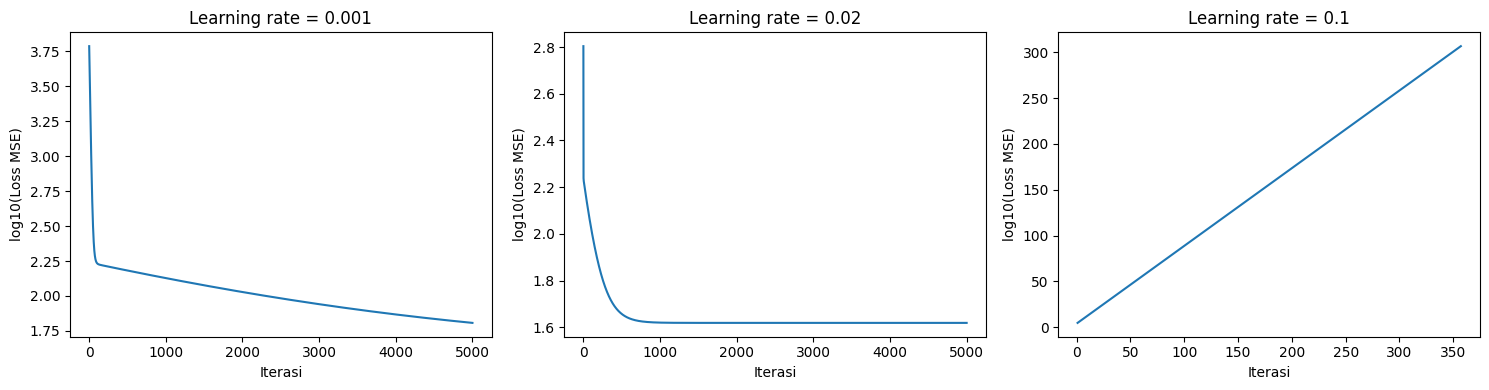

In [7]:
# Jawaban A5
# Implementasi Linear Regression dengan Gradient Descent disalin dari materi
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient

            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_


learning_rates = [0.001, 0.02, 0.1]
model_gd = {}
for lr in learning_rates:
    print(f'--- learning_rate = {lr} ---')
    model_gd[lr] = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)

# Tabel perbandingan dengan normal equation
baris = [{'Metode': 'Normal Equation', 'Intercept': b_ne, 'Koefisien': m_ne,
          'MSE train akhir': mse(y_train, y_pred_train)}]
for lr, mdl in model_gd.items():
    baris.append({'Metode': f'GD lr={lr}', 'Intercept': mdl.intercept_,
                  'Koefisien': mdl.coefficients_[0], 'MSE train akhir': mdl.loss_history_[-1]})
display(pd.DataFrame(baris).set_index('Metode'))

# Iterasi pertama kali loss menjadi tidak berhingga / NaN (jika ada)
for lr, mdl in model_gd.items():
    lh = np.array(mdl.loss_history_)
    bad = np.where(~np.isfinite(lh))[0]
    if len(bad) > 0:
        print(f'lr={lr}: loss menjadi inf/NaN mulai iterasi ke-{bad[0] + 1}; loss terakhir yang masih berhingga = {lh[bad[0] - 1]:.3e}')
    else:
        print(f'lr={lr}: loss selalu berhingga, loss akhir = {lh[-1]:.4f}')

# Grafik loss vs iterasi. Sumbu y memakai log10(loss) agar nilai yang membesar sampai ~1e306 pun masih bisa digambar;
# nilai inf/NaN tidak bisa digambar sehingga kurva yang divergen berhenti tepat sebelum loss menjadi inf.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr in zip(axes, learning_rates):
    lh = np.array(model_gd[lr].loss_history_)
    ok = np.isfinite(lh)
    ax.plot(np.arange(1, len(lh) + 1)[ok], np.log10(lh[ok]))
    ax.set_title(f'Learning rate = {lr}')
    ax.set_xlabel('Iterasi')
    ax.set_ylabel('log10(Loss MSE)')
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

- **lr = 0,001 (terlalu lambat).** Setelah 5000 iterasi hasilnya masih jauh dari solusi normal equation: intercept 17,84 dan koefisien 10,70 (normal equation: 29,04 dan 8,99), dengan MSE training akhir 64,19 dibanding 41,54. Grafik loss masih menurun saat iterasi berhenti, jadi model belum konvergen. Langkah update terlalu kecil sehingga butuh iterasi jauh lebih banyak.
- **lr = 0,02 (pas).** Intercept 29,044362 dan koefisien 8,991226 hampir identik dengan normal equation (29,044363 dan 8,991226), MSE akhir 41,5429 sama. Loss turun cepat lalu mendatar, artinya gradient descent berhasil menemukan solusi minimum yang sama dengan normal equation.
- **lr = 0,1 (divergen).** Loss tidak turun tetapi membesar terus: dari 4,55×10⁴ pada iterasi 1, menjadi 1,96×10¹² pada iterasi 10, lalu 3,2×10¹⁷³ pada iterasi 200, dan mulai iterasi ke-358 menjadi tak hingga/NaN sehingga intercept dan koefisien akhirnya NaN. Penyebabnya langkah update terlalu besar: setiap iterasi melompati titik minimum ke sisi seberang dan mendarat lebih jauh dari sebelumnya. Pada data ini batas kestabilan sekitar 2 dibagi nilai eigen terbesar dari XᵀX/n (36,56), yaitu sekitar 0,055, sehingga 0,02 aman sedangkan 0,1 melewati batas.

`RuntimeWarning: overflow` yang muncul berarti angka sudah melewati batas terbesar yang bisa disimpan komputer (float64, sekitar 10³⁰⁸) sehingga menjadi inf. Itu adalah bukti nyata divergensi, bukan error kode. Pada grafik (sumbu y berupa log10 dari loss), kurva lr = 0,1 naik terus sampai sekitar 306 lalu berhenti di iterasi 357, karena setelah itu nilainya inf/NaN dan tidak bisa digambar.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

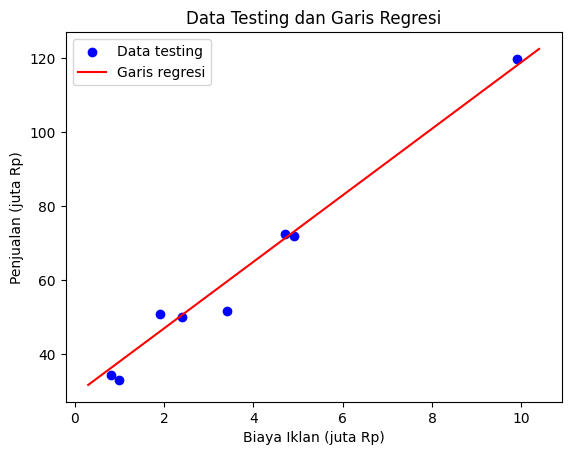

,BiayaIklan (juta),Prediksi Penjualan (juta),Dalam rentang data?
0,4.5,69.5049,True
1,7.0,91.9829,True
2,12.0,136.9391,False


Rentang BiayaIklan pada dataset: 0.8 - 9.9 juta


In [8]:
# Jawaban A6
# 1. Scatter data testing + garis regresi (normal equation)
x_garis = np.linspace(X.min() - 0.5, X.max() + 0.5, 100).reshape(-1, 1)
plt.scatter(X_test, y_test, c='blue', label='Data testing')
plt.plot(x_garis, regressor.predict(x_garis), c='red', label='Garis regresi')
plt.title('Data Testing dan Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.show()

# 2. Prediksi untuk biaya iklan baru
biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_baru = regressor.predict(biaya_baru)
tabel_prediksi = pd.DataFrame({'BiayaIklan (juta)': biaya_baru[:, 0],
                               'Prediksi Penjualan (juta)': prediksi_baru})
tabel_prediksi['Dalam rentang data?'] = (biaya_baru[:, 0] >= X.min()) & (biaya_baru[:, 0] <= X.max())
display(tabel_prediksi.round(4))
print(f'Rentang BiayaIklan pada dataset: {X.min()} - {X.max()} juta')

**Jawaban A6 (analisis):**

Prediksi dari persamaan ŷ = 29,0444 + 8,9912·X: biaya iklan 4,5 juta → penjualan sekitar 69,50 juta, 7 juta → 91,98 juta, dan 12 juta → 136,94 juta.

Prediksi 4,5 dan 7 juta berada di dalam rentang data (0,8–9,9 juta) sehingga cukup bisa dipercaya, sejalan dengan R² testing 0,9785. Prediksi 12 juta adalah ekstrapolasi karena biaya iklan tersebut lebih besar dari semua data yang pernah dilihat model. Hasilnya 136,94 juta melebihi penjualan tertinggi di data (121,1 juta), dan itu hanya hasil memperpanjang garis lurus. Dalam kenyataan efek iklan bisa melandai karena pasar mulai jenuh, jadi menurut saya angka ini kurang bisa dipercaya dan sebaiknya hanya dipakai sebagai perkiraan kasar, bukan dasar keputusan, sampai ada data pada biaya iklan setinggi itu.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

Kolom : ['JumlahLink', 'KataPromo', 'Spam']
5 data pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah data : 60
Jumlah email Bukan Spam (0) : 35
Jumlah email Spam (1)       : 25
Shape X : (60, 2) | Shape y : (60,)


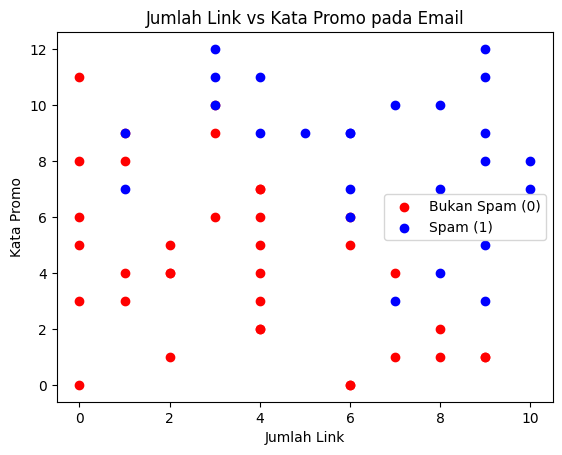

In [9]:
# Jawaban B1
email_data = pd.read_csv('Email_Data.csv')
print('Kolom :', list(email_data.columns))
print('5 data pertama:')
display(email_data.head())
print('Jumlah data :', len(email_data))

jumlah_kelas = email_data['Spam'].value_counts().sort_index()
print('Jumlah email Bukan Spam (0) :', jumlah_kelas[0])
print('Jumlah email Spam (1)       :', jumlah_kelas[1])

X = email_data[['JumlahLink', 'KataPromo']].values
y = email_data['Spam'].values
print('Shape X :', X.shape, '| Shape y :', y.shape)

plt.scatter(X[y == 0, 0], X[y == 0, 1], c='red', label='Bukan Spam (0)')
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='blue', label='Spam (1)')
plt.title('Jumlah Link vs Kata Promo pada Email')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2) | X_test: (15, 2)
y_train: (45,) | y_test: (15,)
Proporsi Spam di training: 0.3556 | di testing: 0.6
Intercept (b)       : -8.7729
Koefisien m1 (Link) : 0.7336
Koefisien m2 (Promo): 0.7335
P(Spam) = sigmoid(-8.7729 + 0.7336 * JumlahLink + 0.7335 * KataPromo)
Log loss iterasi     1: 0.693147
Log loss iterasi   100: 0.560878
Log loss iterasi  1000: 0.349801
Log loss iterasi  5000: 0.316296
Log loss iterasi 10000: 0.315365
Selisih loss iterasi 9000 -> 10000: 3.18e-05


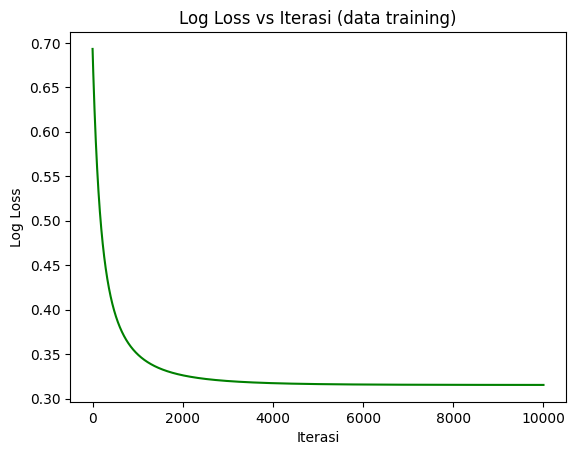

In [10]:
# Jawaban B2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('y_train:', y_train.shape, '| y_test:', y_test.shape)
print('Proporsi Spam di training:', round(y_train.mean(), 4), '| di testing:', round(y_test.mean(), 4))

# Implementasi Logistic Regression disalin dari materi
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta = beta - self.learning_rate * gradient

            p = np.clip(p, 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict_proba(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self._sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


classifier = LogisticRegression(learning_rate=0.1, n_iterations=10000)
classifier.fit(X_train, y_train)

b = classifier.intercept_
m1, m2 = classifier.coefficients_
print(f'Intercept (b)       : {b:.4f}')
print(f'Koefisien m1 (Link) : {m1:.4f}')
print(f'Koefisien m2 (Promo): {m2:.4f}')
print(f'P(Spam) = sigmoid({b:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)')

lh = np.array(classifier.loss_history_)
for it in [1, 100, 1000, 5000, 10000]:
    print(f'Log loss iterasi {it:>5}: {lh[it - 1]:.6f}')
print(f'Selisih loss iterasi 9000 -> 10000: {lh[8999] - lh[9999]:.2e}')

plt.plot(np.arange(1, len(lh) + 1), lh, c='green')
plt.title('Log Loss vs Iterasi (data training)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.show()

**Jawaban B2 (analisis):**

Data dibagi menjadi 45 training dan 15 testing. Model menghasilkan b = -8,7729, m₁ = 0,7336 (JumlahLink), dan m₂ = 0,7335 (KataPromo), sehingga P(Spam) = σ(-8,7729 + 0,7336·JumlahLink + 0,7335·KataPromo). Kedua koefisien positif dan hampir sama besar, artinya semakin banyak link dan kata promosi, semakin besar peluang email dianggap spam, dengan bobot yang hampir sama untuk keduanya.

Pada grafik, log loss turun tajam di awal (0,6931 pada iterasi 1 menjadi 0,5609 pada iterasi 100 dan 0,3498 pada iterasi 1000), lalu melandai menjadi 0,3163 pada iterasi 5000 dan 0,3154 pada iterasi 10000. Selisih loss dari iterasi 9000 ke 10000 hanya sekitar 3×10⁻⁵, jadi loss sudah turun dan hampir stabil. Namun pada bagian bonus terlihat parameternya masih bergeser sedikit jika iterasi ditambah, sehingga saya menyebutnya "hampir" stabil, bukan benar-benar konvergen penuh.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

Accuracy  : 1.0
Precision : 1.0
Recall    : 1.0
F1-score  : 1.0

Confusion Matrix (baris = aktual, kolom = prediksi):


,Prediksi Bukan Spam,Prediksi Spam
Aktual Bukan Spam,6,0
Aktual Spam,0,9


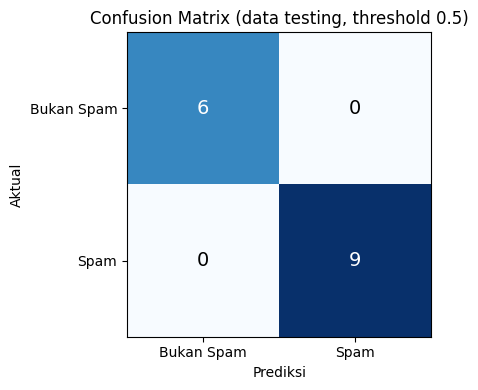

In [11]:
# Jawaban B3
# Metrik klasifikasi (implementasi sendiri dengan NumPy)
def accuracy_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    return np.array([[tn, fp],
                     [fn, tp]])

def precision_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    if tp + fp == 0:         # tidak ada prediksi positif -> precision tidak terdefinisi
        return np.nan
    return tp / (tp + fp)

def recall_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    if tp + fn == 0:         # tidak ada data positif asli -> recall tidak terdefinisi
        return np.nan
    return tp / (tp + fn)

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    if np.isnan(p) or np.isnan(r):
        return np.nan
    if p + r == 0:           # precision = recall = 0
        return 0.0
    return 2 * p * r / (p + r)

y_pred = classifier.predict(X_test)          # threshold default 0.5
cm = confusion_matrix(y_test, y_pred)

print('Accuracy  :', round(accuracy_score(y_test, y_pred), 4))
print('Precision :', round(precision_score(y_test, y_pred), 4))
print('Recall    :', round(recall_score(y_test, y_pred), 4))
print('F1-score  :', round(f1_score(y_test, y_pred), 4))
print()
print('Confusion Matrix (baris = aktual, kolom = prediksi):')
display(pd.DataFrame(cm, index=['Aktual Bukan Spam', 'Aktual Spam'],
                     columns=['Prediksi Bukan Spam', 'Prediksi Spam']))

# Visualisasi confusion matrix
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(['Bukan Spam', 'Spam']); ax.set_yticklabels(['Bukan Spam', 'Spam'])
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
ax.set_title('Confusion Matrix (data testing, threshold 0.5)')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()

**Jawaban B3 (analisis):**

Pada 15 data testing (threshold 0,5) hasilnya: accuracy 1,0000, precision 1,0000, recall 1,0000, dan F1 1,0000, dengan confusion matrix TN = 6, FP = 0, FN = 0, TP = 9. Artinya semua email testing diklasifikasikan benar. Hasil sempurna ini perlu dibaca hati-hati karena data testing hanya 15 email, dan berisi lebih banyak spam (9 dari 15 = 60%) dibanding data training (sekitar 36%), jadi tidak berarti model akan selalu sempurna pada email baru.

**FP (false positive)** adalah email yang sebenarnya bukan spam tetapi dikira spam, sedangkan **FN (false negative)** adalah email spam yang lolos dan dianggap bukan spam. Menurut saya FP lebih merugikan pengguna, karena email penting seperti info pekerjaan, tagihan, atau kuliah bisa masuk folder spam dan tidak terbaca. FN hanya membuat pengguna menerima satu email spam di inbox yang bisa langsung dihapus.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: x2 = -(-8.7729 + 0.7336 * x1) / 0.7335
                   x2 = 11.9599 + (-1.0001) * x1


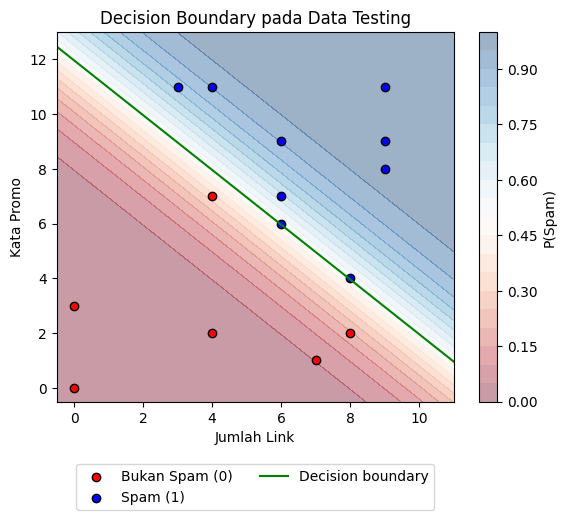

Jumlah data testing yang salah diklasifikasikan: 0 dari 15
Tidak ada data testing yang salah diklasifikasikan.


In [12]:
# Jawaban B4
# Persamaan decision boundary: x2 = -(b + m1*x1) / m2
b = classifier.intercept_
m1, m2 = classifier.coefficients_
print(f'Decision boundary: x2 = -({b:.4f} + {m1:.4f} * x1) / {m2:.4f}')
print(f'                   x2 = {-b / m2:.4f} + ({-m1 / m2:.4f}) * x1')

x1, x2 = np.meshgrid(np.linspace(-0.5, 11, 200), np.linspace(-0.5, 13, 200))
grid = np.c_[x1.ravel(), x2.ravel()]
proba = classifier.predict_proba(grid).reshape(x1.shape)
x1_line = np.linspace(-0.5, 11, 100)
x2_line = -(b + m1 * x1_line) / m2

y_pred = classifier.predict(X_test)
salah = y_pred != y_test

plt.contourf(x1, x2, proba, levels=20, cmap='RdBu', alpha=0.4)
plt.colorbar(label='P(Spam)')
plt.scatter(X_test[(y_test == 0), 0], X_test[(y_test == 0), 1], c='red', edgecolors='k', label='Bukan Spam (0)')
plt.scatter(X_test[(y_test == 1), 0], X_test[(y_test == 1), 1], c='blue', edgecolors='k', label='Spam (1)')
if salah.any():
    plt.scatter(X_test[salah, 0], X_test[salah, 1], s=250, facecolors='none', edgecolors='black',
                linewidths=2, label='Salah klasifikasi')
plt.plot(x1_line, x2_line, c='g', label='Decision boundary')
plt.xlim(-0.5, 11)
plt.ylim(-0.5, 13)
plt.title('Decision Boundary pada Data Testing')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.show()

print('Jumlah data testing yang salah diklasifikasikan:', int(salah.sum()), 'dari', len(y_test))
if salah.any():
    display(pd.DataFrame({'JumlahLink': X_test[salah, 0], 'KataPromo': X_test[salah, 1],
                          'Aktual': y_test[salah], 'Prediksi': y_pred[salah]}))
else:
    print('Tidak ada data testing yang salah diklasifikasikan.')

**Jawaban B4 (analisis):**

Decision boundary-nya x₂ = -(-8,7729 + 0,7336·x₁) / 0,7335 ≈ 11,96 − 1,0001·x₁. Karena m₁ dan m₂ hampir sama, garisnya hampir tepat x₁ + x₂ ≈ 12: email diprediksi spam jika jumlah link ditambah jumlah kata promo sekitar 12 atau lebih. Pada grafik, titik biru (spam) berada di sisi kanan atas garis dan titik merah (bukan spam) di sisi kiri bawah.

Jumlah data testing yang salah diklasifikasikan adalah 0 dari 15, sehingga tidak ada titik yang diberi lingkaran hitam penanda salah klasifikasi (kode penandanya tetap disediakan dan akan muncul jika ada kesalahan). Ada dua email testing yang probabilitasnya 0,507, sangat dekat dengan garis, jadi benar secara kebetulan tipis. Kalau data berubah sedikit saja, keduanya bisa jatuh ke sisi yang salah.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
y_proba = classifier.predict_proba(X_test)

baris = []
for t in [0.3, 0.5, 0.7]:
    y_pred_t = classifier.predict(X_test, threshold=t)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    baris.append({'Threshold': t, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                  'Accuracy': accuracy_score(y_test, y_pred_t),
                  'Precision': precision_score(y_test, y_pred_t),
                  'Recall': recall_score(y_test, y_pred_t),
                  'F1': f1_score(y_test, y_pred_t)})
tabel_threshold = pd.DataFrame(baris).set_index('Threshold')
display(tabel_threshold.round(4))

# Probabilitas data testing yang paling dekat dengan batas keputusan
print('Probabilitas data testing, diurutkan:')
print(np.sort(y_proba).round(3))

THRESHOLD_PILIHAN = 0.5   # threshold yang dipakai pada Soal B6 (alasan di sel markdown di bawah)
print('Threshold pilihan:', THRESHOLD_PILIHAN)

,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
Threshold,,,,,,,,
0.3,5,1,0,9,0.9333,0.9,1.0000,0.9474
0.5,6,0,0,9,1.0000,1.0,1.0000,1.0000
0.7,6,0,3,6,0.8000,1.0,0.6667,0.8000


Probabilitas data testing, diurutkan:
[0.    0.001 0.012 0.052 0.192 0.331 0.507 0.507 0.682 0.817 0.903 0.903
 0.976 0.988 0.997]
Threshold pilihan: 0.5


**Jawaban B5 (analisis):**

| Threshold | FP | FN | Precision | Recall |
|---|---|---|---|---|
| 0,3 | 1 | 0 | 0,9000 | 1,0000 |
| 0,5 | 0 | 0 | 1,0000 | 1,0000 |
| 0,7 | 0 | 3 | 1,0000 | 0,6667 |

Menurunkan threshold membuat model lebih "mudah" menyebut email sebagai spam: recall tetap 1,0 tetapi satu email bukan spam ikut terjaring (FP = 1) sehingga precision turun menjadi 0,90. Menaikkan threshold membuat model lebih "hati-hati": precision tetap 1,0 tetapi 3 email spam lolos (FN = 3) sehingga recall turun menjadi 0,6667. Jadi precision dan recall saling tarik-menarik.

Saya memilih **threshold 0,5**. Pada data testing ini nilai tersebut memberi FP = 0 dan FN = 0. Berdasarkan Soal B3, FP lebih merugikan sehingga threshold tidak saya turunkan ke 0,3, sementara menaikkannya ke 0,7 membuat 3 spam lolos tanpa tambahan manfaat pada data ini. Kalau di aplikasi nyata pengguna sangat takut email penting terblokir, threshold bisa dinaikkan sedikit, tetapi 0,7 menurut saya sudah terlalu longgar untuk spam.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
email_baru = pd.DataFrame({'Email': ['E1', 'E2', 'E3', 'E4'],
                           'JumlahLink': [1, 5, 9, 2],
                           'KataPromo': [2, 6, 10, 11]})
X_baru = email_baru[['JumlahLink', 'KataPromo']].values
email_baru['P(Spam)'] = classifier.predict_proba(X_baru)
email_baru['Prediksi'] = np.where(classifier.predict(X_baru, threshold=THRESHOLD_PILIHAN) == 1,
                                  'Spam', 'Bukan Spam')
print('Threshold yang dipakai:', THRESHOLD_PILIHAN)
display(email_baru.round(4))

Threshold yang dipakai: 0.5


,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.0014,Bukan Spam
1,E2,5,6,0.3309,Bukan Spam
2,E3,9,10,0.9943,Spam
3,E4,2,11,0.6820,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk klasifikasi karena keluarannya adalah probabilitas kelas (antara 0 dan 1) yang kemudian diubah menjadi label (misalnya spam atau bukan spam) memakai threshold, bukan nilai kontinu seperti pada regresi biasa. Kata "regression" berasal dari bagian awalnya yang masih menghitung kombinasi linear b + m₁x₁ + m₂x₂. Fungsi sigmoid σ(z) = 1/(1 + e⁻ᶻ) mengubah nilai z yang bisa berapa saja menjadi angka di antara 0 dan 1 sehingga bisa dibaca sebagai peluang. Pada percobaan saya, email E3 (9 link, 10 kata promo) mendapat P(Spam) = 0,9943 dan E1 (1 link, 2 kata promo) hanya 0,0014.

**Jawaban C2:**
Normal equation menghitung parameter langsung dalam satu kali hitung memakai rumus matriks β = (XᵀX)⁻¹Xᵀy, sedangkan gradient descent mencarinya bertahap dengan memperbarui parameter searah penurunan loss sebanyak sekian iterasi. Normal equation tidak perlu learning rate, tetapi butuh membalik matriks yang menjadi berat jika fitur sangat banyak atau matriksnya hampir singular. Gradient descent lebih cocok untuk data atau jumlah fitur besar, dan bisa dipakai pada model yang tidak punya rumus langsung seperti Logistic Regression, tetapi hasilnya bergantung pada learning rate dan jumlah iterasi. Di percobaan A5, lr = 0,02 menghasilkan koefisien 8,9912, sama dengan normal equation, sedangkan lr = 0,001 belum sampai dan lr = 0,1 divergen.

**Jawaban C3:**
Data testing dipakai karena model sudah "melihat" data training saat belajar, sehingga nilai di data training bisa terlalu optimis dan tidak menunjukkan kemampuan pada data yang belum pernah dilihat. Evaluasi pada data testing memberi gambaran yang lebih jujur tentang performa sebenarnya. Overfitting adalah kondisi saat model terlalu menyesuaikan diri pada data training (termasuk noise-nya) sehingga bagus di training tetapi buruk di data baru. Tandanya error training sangat kecil tetapi error testing jauh lebih besar. Pada model saya tidak terlihat tanda itu (RMSE training 6,45 dan testing 3,84), tetapi data testing yang hanya 8 titik membuat kesimpulan ini belum kuat.

**Jawaban C4:**
Linear Regression menghasilkan angka kontinu sehingga kesalahan wajar diukur dengan selisih kuadrat (MSE), dan fungsi ini mulus serta cocok dengan solusi kuadrat. Logistic Regression menghasilkan probabilitas untuk label 0 atau 1, dan MSE kurang cocok untuk itu karena kurva loss-nya tidak cembung terhadap parameter sehingga gradient descent bisa tersendat. Log loss, yaitu −[y·log(p) + (1−y)·log(1−p)], memberi hukuman sangat besar saat model yakin tetapi salah (misalnya p mendekati 0 padahal kelas sebenarnya 1), dan bersifat cembung sehingga cocok untuk gradient descent. Di percobaan saya log loss training turun dari 0,6931 menjadi 0,3154.

**Jawaban C5:**
Angka bisa berbeda terutama karena pembagian data training dan testing bergantung pada random_state yang berbeda tiap mahasiswa (saya memakai 73), sehingga data yang masuk ke training dan testing juga berbeda. Pada data kecil seperti ini perbedaan tersebut berpengaruh besar: misalnya data testing email saya berisi 60% spam sedangkan training hanya sekitar 36%. Selain itu, hasil juga bisa berbeda jika learning rate, jumlah iterasi, atau threshold yang dipilih tidak sama, karena gradient descent berhenti di titik yang berbeda atau memberi label yang berbeda pada data yang sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus
# scikit-learn HANYA dipakai di sel ini untuk membandingkan, bukan untuk implementasi utama.
import sklearn
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
print('Versi scikit-learn:', sklearn.__version__)

# ---------- Bonus 1: Linear Regression (data Ads, split yang sama) ----------
Xa = ads_data[['BiayaIklan']].values
ya = ads_data['Penjualan'].values
Xa_train, Xa_test, ya_train, ya_test = train_test_split(Xa, ya, test_size=0.2, random_state=RANDOM_STATE)

sk_lin = SkLinearRegression().fit(Xa_train, ya_train)
pred_sk_lin = sk_lin.predict(Xa_test)
pred_my_lin = regressor.predict(Xa_test)

print('=== Linear Regression ===')
display(pd.DataFrame({
    'Intercept': [regressor.intercept_, sk_lin.intercept_],
    'Koefisien': [regressor.coefficients_[0], sk_lin.coef_[0]],
    'MAE test': [mae(ya_test, pred_my_lin), mae(ya_test, pred_sk_lin)],
    'RMSE test': [rmse(ya_test, pred_my_lin), rmse(ya_test, pred_sk_lin)],
    'R2 test': [r2_score(ya_test, pred_my_lin), r2_score(ya_test, pred_sk_lin)],
}, index=['Implementasi sendiri', 'scikit-learn']))
print('Selisih absolut koefisien :', abs(regressor.coefficients_[0] - sk_lin.coef_[0]))
print('Selisih absolut intercept :', abs(regressor.intercept_ - sk_lin.intercept_))

# ---------- Bonus 2: Logistic Regression (data Email, split yang sama) ----------
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    email_data[['JumlahLink', 'KataPromo']].values, email_data['Spam'].values,
    test_size=0.25, random_state=RANDOM_STATE)

sk_log_default = SkLogisticRegression().fit(Xe_train, ye_train)                    # default: L2, C=1.0
sk_log_lemah = SkLogisticRegression(C=1e10, max_iter=10000).fit(Xe_train, ye_train)  # regularisasi hampir nol

def ringkas(nama, intercept, koef, pred_test, proba_test):
    return {'Model': nama, 'Intercept': intercept, 'm1 (Link)': koef[0], 'm2 (Promo)': koef[1],
            'Accuracy': accuracy_score(ye_test, pred_test),
            'Precision': precision_score(ye_test, pred_test),
            'Recall': recall_score(ye_test, pred_test),
            'F1': f1_score(ye_test, pred_test),
            'Rata2 P(Spam) data Spam': proba_test[ye_test == 1].mean()}

proba_my = classifier.predict_proba(Xe_test)
tabel_log = pd.DataFrame([
    ringkas('Implementasi sendiri (tanpa regularisasi)', classifier.intercept_, classifier.coefficients_,
            classifier.predict(Xe_test), proba_my),
    ringkas('sklearn default (L2, C=1.0)', sk_log_default.intercept_[0], sk_log_default.coef_[0],
            sk_log_default.predict(Xe_test), sk_log_default.predict_proba(Xe_test)[:, 1]),
    ringkas('sklearn C=1e10 (regularisasi ~0)', sk_log_lemah.intercept_[0], sk_log_lemah.coef_[0],
            sk_log_lemah.predict(Xe_test), sk_log_lemah.predict_proba(Xe_test)[:, 1]),
]).set_index('Model')
print('=== Logistic Regression ===')
display(tabel_log.round(4))
print('Confusion matrix sklearn default:')
print(confusion_matrix(ye_test, sk_log_default.predict(Xe_test)))
print('Confusion matrix sklearn C=1e10 :')
print(confusion_matrix(ye_test, sk_log_lemah.predict(Xe_test)))
# Pembuktian: apakah selisih dengan sklearn C=1e10 hanya karena GD (10000 iterasi) belum konvergen penuh?
classifier_100k = LogisticRegression(learning_rate=0.1, n_iterations=100000).fit(Xe_train, ye_train)
print()
print('Implementasi sendiri, 10.000 iterasi :', np.round([classifier.intercept_, *classifier.coefficients_], 4))
print('Implementasi sendiri, 100.000 iterasi:', np.round([classifier_100k.intercept_, *classifier_100k.coefficients_], 4))
print('sklearn C=1e10                       :', np.round([sk_log_lemah.intercept_[0], *sk_log_lemah.coef_[0]], 4))

Versi scikit-learn: 1.0.2
=== Linear Regression ===


,Intercept,Koefisien,MAE test,RMSE test,R2 test
Implementasi sendiri,29.044363,8.991226,2.990478,3.841442,0.978497
scikit-learn,29.044363,8.991226,2.990478,3.841442,0.978497


Selisih absolut koefisien : 2.3092638912203256e-14
Selisih absolut intercept : 2.0961010704922955e-13
=== Logistic Regression ===


,Intercept,m1 (Link),m2 (Promo),Accuracy,Precision,Recall,F1,Rata2 P(Spam) data Spam
Model,,,,,,,,
Implementasi sendiri (tanpa regularisasi),-8.7729,0.7336,0.7335,1.0000,1.0,1.0000,1.000,0.8090
"sklearn default (L2, C=1.0)",-8.1793,0.6778,0.6832,0.8667,1.0,0.7778,0.875,0.7962
sklearn C=1e10 (regularisasi ~0),-8.9232,0.7467,0.7460,1.0000,1.0,1.0000,1.000,0.8112


Confusion matrix sklearn default:
[[6 0]
 [2 7]]
Confusion matrix sklearn C=1e10 :
[[6 0]
 [0 9]]

Implementasi sendiri, 10.000 iterasi : [-8.7729  0.7336  0.7335]
Implementasi sendiri, 100.000 iterasi: [-8.9232  0.7467  0.746 ]
sklearn C=1e10                       : [-8.9232  0.7467  0.746 ]


**Jawaban Bonus (analisis):**

**Linear Regression.** `sklearn.linear_model.LinearRegression` menghasilkan intercept 29,0444 dan koefisien 8,9912, sama dengan implementasi saya. Selisih absolutnya hanya sekitar 10⁻¹³ sampai 10⁻¹⁴ (galat pembulatan komputer), dan MAE, RMSE, serta R² testing juga sama (2,9905; 3,8414; 0,9785). Ini wajar karena keduanya menyelesaikan masalah kuadrat terkecil yang sama dengan solusi tertutup.

**Logistic Regression.** Hasil scikit-learn **tidak sama** dengan implementasi saya jika memakai pengaturan default. Pada default (`penalty='l2'`, `C=1.0`) koefisiennya lebih kecil: intercept -8,1802, m₁ = 0,6779, m₂ = 0,6833 dibanding milik saya -8,7729, 0,7336, 0,7335. Penyebabnya, scikit-learn secara default menambahkan regularisasi L2 yang menarik koefisien mendekati nol, sedangkan implementasi saya tidak memakai regularisasi. Akibatnya probabilitas sklearn lebih "landai", dan pada threshold 0,5 dua email spam di data testing jadi lolos (confusion matrix [[6, 0], [2, 7]]) dengan accuracy 0,8667, precision 1,0, recall 0,7778, dan F1 0,875, lebih rendah dari milik saya yang 1,0 semua.

Saat regularisasi hampir dihilangkan (`C=1e10`), accuracy, precision, recall, dan F1 sklearn menjadi 1,0 seperti milik saya, dan koefisiennya mendekati (-8,9231; 0,7467; 0,7460). Masih ada selisih kecil karena gradient descent saya berhenti di 10.000 iterasi. Setelah dilatih 100.000 iterasi, koefisien implementasi saya menjadi -8,9232; 0,7467; 0,7460, sehingga selisihnya dengan sklearn C=1e10 tinggal sekitar 0,0001 (pembulatan di angka desimal ke-4). Jadi perbedaan datang dari regularisasi (utama) dan jumlah iterasi (kecil), bukan dari kesalahan implementasi.